# Assignment 8 — Movie Recommendation Systems

**Juan Luna Santibanez**  
**Miami Dade College · CAI2100C-2267-6908 · Machine Learning Foundations**  
**Professor Beth Muturi**

## My assignment and my data sources

I built **one notebook** with the two final tasks in the instructor's notebook:

1. **Task 1: IMDb Extensive — Content-Based Filtering** using TF-IDF and cosine similarity.
2. **Task 2: IMDb Extensive — Collaborative Filtering approximation** using average ratings from six demographic groups. This dataset contains aggregated cohort means, **not individual users or Surprise SVD**.

I added a **separate MovieLens/TMDB classroom extension** because my instructor's follow-up email requested both datasets. I document the distinction between the teacher's ZIP and the public Kaggle collection; I do not claim that two copies are byte-identical unless I have checked them.

**Automatic loading:** My notebook first uses the authentic files already attached, then downloads only the necessary CSVs with **Kaggle's official `kagglehub` library**. If Kaggle is inaccessible, I try the **pinned IMDb Kaggle-data mirror** documented in my project's provenance. I also try a public MovieLens mirror for the optional classroom extension. I never substitute simulated movies for missing authentic data. Downloading requires internet access and may require Kaggle authorization depending on account/network restrictions.

**References:** [IMDb Extensive](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset) · [MovieLens/TMDB classroom source](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset) · [Kagglehub](https://github.com/Kaggle/kagglehub) · [Rounak Banik's recommender lesson](https://www.kaggle.com/code/rounakbanik/movie-recommender-systems).

**Project links:** [GitHub](https://github.com/SupaHumano/CAI2100C-Movie-Recommendation-Systems) · [Google Colab](https://colab.research.google.com/github/SupaHumano/CAI2100C-Movie-Recommendation-Systems/blob/main/notebooks/Assignment_8_Juan_Luna_Santibanez_Movie_Recommendation_Systems.ipynb) · [Presentation](https://github.com/SupaHumano/CAI2100C-Movie-Recommendation-Systems/blob/main/docs/PRESENTATION_GUIDE.md) · [Interactive fictional teaching demo](https://supahumano.github.io/CAI2100C-Movie-Recommendation-Systems/).

**Evidence standard:** I save authentic numeric results only after I actually run this notebook against the real CSVs. Synthetic test fixtures are not evidence of IMDb or MovieLens results.


## My single-file, reproducible research submission

I prepared one offline notebook containing **five compressed, integrity-checked snapshots of authentic source CSVs**. It runs with **Runtime → Run all**, without external files, passwords, manual uploads or network access.

- **Required IMDb assignments:** my snapshot includes the 3,000 high-vote movies analyzed by my code and corresponding IMDb cohort-average ratings.
- **MovieLens/TMDB extension:** my snapshot includes the small MovieLens rating and link tables and metadata restricted to linked films.
- The embedded subsets **are not** the complete 85,855-record IMDb dataset or the teacher's large original ZIP. I identify each source and full original-file fingerprints in the provenance cell; I do not mislabel or inflate row counts.
- I reproduce content-based recommendations and held-out cohort/user-based collaborative evaluations with the same input snapshots used to generate the saved outputs.

**Sources and academic attribution:** [Stefano Leone's IMDb Extensive](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset), pinned [IMDb dataset mirror](https://github.com/Abkas/Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/tree/509c026e32a6fa78cfc987a0aa39f47cc47fd243/Dataset), and [Rounak Banik's MovieLens/TMDB collection](https://www.kaggle.com/rounakbanik/the-movies-dataset). Embedded data are for educational research; I do not claim to redistribute the full original sources.


## Embedded research snapshots — integrity and scope

- **IMDb movies.csv**: 3,000 rows · SHA-256 `cd05f6b6d71f636574f64ebe673e76b750725f13122146f3ae6e4e077c11fa18` · [source](https://raw.githubusercontent.com/Abkas/Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/509c026e32a6fa78cfc987a0aa39f47cc47fd243/Dataset/IMDb%20movies.csv)
- **IMDb ratings.csv**: 3,000 rows · SHA-256 `302b468d63233239a85f890e2fcd5e33fe3e4cab59f42a141280be4341388fb8` · [source](https://raw.githubusercontent.com/Abkas/Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/509c026e32a6fa78cfc987a0aa39f47cc47fd243/Dataset/IMDb%20ratings.csv)
- **movies_metadata.csv**: 9,099 rows · SHA-256 `fd00fcc075f309017a34700413653cb852f801e37c4ae40c3fdc7612e6456cb8` · [source](https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/movies_metadata.csv)
- **links_small.csv**: 9,125 rows · SHA-256 `566ba56a4fac2423df22137e3c0d22dd33b3069281af22e811e353bc68afbd72` · [source](https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/links_small.csv)
- **ratings_small.csv**: 100,004 rows · SHA-256 `b4239649fbf90ebf405c56c3ae1d929d9e7c86fc1a3a80cbef1c884df593ef73` · [source](https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/ratings_small.csv)

**Full original IMDb CSV hashes (pre-subsetting):** `IMDb movies.csv` = `0a106f5bd8de699cd092b0e02e6968ffb4ecde8b1c13b1ec899c3eb6873e8122`, `IMDb ratings.csv` = `92a29e0eb24fdd7f8977378e08aa59de5f3bab2433c6eef508af85e59a222675`

MovieLens snapshots originate from a separate, pinned public source. I do not identify them as byte-identical to the instructor’s ZIP. The large full MovieLens `ratings.csv` is **not** embedded, since the classroom model uses `ratings_small.csv`.

### 00 — Dataset integrity (verified and included)

I included five **authentic source-data research snapshots** inside this notebook. The code that contains compressed data is displayed as a **collapsed execution form in Google Colab**, so readers can focus on the methods, charts and conclusions. Run all cells normally; no CSV downloads or manual configuration are required. The cell can be expanded to audit its contents.

**Sources:** 3,000 selected IMDb movies and 3,000 matching IMDb cohort-rating rows; 9,099 MovieLens/TMDB metadata rows, 9,125 ID links, 100,004 individual ratings. This is a documented research sample, **not the entire original IMDb database**.


In [1]:
# @title 00 · Cargar los 5 datasets auténticos integrados (sin descargas) { display-mode: "form" }
# @markdown Esta celda ejecuta la verificación SHA-256 y extrae los archivos ya incluidos. El bloque técnico permanece plegado.
# My original-data research snapshots are embedded inside this notebook.
# No internet, authentication, file uploads or Kaggle access are required.
from pathlib import Path as _EmbeddedPath
import base64 as _embedded_b64, gzip as _embedded_gzip, hashlib as _embedded_hashlib, tempfile as _embedded_tempfile
_EMBEDDED_FILES = {'IMDb movies.csv': '...', 'IMDb ratings.csv': '...', 'movies_metadata.csv': '...', 'links_small.csv': '...', 'ratings_small.csv': '...'}
_EMBEDDED_META = {'IMDb movies.csv': {'rows': 3000, 'size_csv': 1365983, 'size_gzip': 615171, 'snapshot_sha256': 'cd05f6b6d71f636574f64ebe673e76b750725f13122146f3ae6e4e077c11fa18', 'original_source_url': 'https://raw.githubusercontent.com/Abkas/Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/509c026e32a6fa78cfc987a0aa39f47cc47fd243/Dataset/IMDb%20movies.csv'}, 'IMDb ratings.csv': {'rows': 3000, 'size_csv': 238143, 'size_gzip': 81935, 'snapshot_sha256': '302b468d63233239a85f890e2fcd5e33fe3e4cab59f42a141280be4341388fb8', 'original_source_url': 'https://raw.githubusercontent.com/Abkas/Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/509c026e32a6fa78cfc987a0aa39f47cc47fd243/Dataset/IMDb%20ratings.csv'}, 'movies_metadata.csv': {'rows': 9099, 'size_csv': 3384348, 'size_gzip': 1457750, 'snapshot_sha256': 'fd00fcc075f309017a34700413653cb852f801e37c4ae40c3fdc7612e6456cb8', 'original_source_url': 'https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/movies_metadata.csv'}, 'links_small.csv': {'rows': 9125, 'size_csv': 181850, 'size_gzip': 78845, 'snapshot_sha256': '566ba56a4fac2423df22137e3c0d22dd33b3069281af22e811e353bc68afbd72', 'original_source_url': 'https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/links_small.csv'}, 'ratings_small.csv': {'rows': 100004, 'size_csv': 2338261, 'size_gzip': 659364, 'snapshot_sha256': 'b4239649fbf90ebf405c56c3ae1d929d9e7c86fc1a3a80cbef1c884df593ef73', 'original_source_url': 'https://raw.githubusercontent.com/nmsohn/kaggle-movie/751ce2616c0aa7667b93277c37365b0c4edbc929/ratings_small.csv'}}
_EMBEDDED_DIR = _EmbeddedPath(_embedded_tempfile.mkdtemp(prefix='a8_verified_'))
for _filename,_payload in _EMBEDDED_FILES.items():
    _raw = _embedded_gzip.decompress(_embedded_b64.b64decode(_payload))
    _fingerprint = _embedded_hashlib.sha256(_raw).hexdigest()
    assert _fingerprint == _EMBEDDED_META[_filename]['snapshot_sha256'], 'Embedded academic data failed integrity verification: ' + _filename
    (_EMBEDDED_DIR/_filename).write_bytes(_raw)
print('I verified 5 embedded academic research snapshots:', {k: v['rows'] for k,v in _EMBEDDED_META.items()})


I verified 5 embedded academic research snapshots: {'IMDb movies.csv': 3000, 'IMDb ratings.csv': 3000, 'movies_metadata.csv': 9099, 'links_small.csv': 9125, 'ratings_small.csv': 100004}


In [2]:
from pathlib import Path
from zipfile import ZipFile
import os, sys, platform, hashlib, importlib, subprocess, shutil, tempfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix
from IPython.display import display

np.random.seed(42)
IMDB_KAGGLE = 'stefanoleone992/imdb-extensive-dataset'
CLASSROOM_KAGGLE = 'rounakbanik/the-movies-dataset'
PINNED_IMDB_GITHUB = '509c026e32a6fa78cfc987a0aa39f47cc47fd243'
# Reference: docs/IMDb_DATA_PROVENANCE.json in my repository.
IMDB_EXPECTED_SHA256 = {
    'IMDb movies.csv':_EMBEDDED_META['IMDb movies.csv']['snapshot_sha256'],
    'IMDb ratings.csv':_EMBEDDED_META['IMDb ratings.csv']['snapshot_sha256']
}
ROOTS = list(dict.fromkeys(p for p in [Path.cwd(),Path.cwd()/'data',Path('/content'),
    Path('/content/data'),Path('/kaggle/input'),Path('/kaggle/working') ] if p.is_dir()))
DATA_PATHS, DATA_ORIGINS, DATA_ERRORS = {}, {}, {}
DATA_PATHS.update({name: _EMBEDDED_DIR/name for name in _EMBEDDED_FILES})
DATA_ORIGINS.update({name: 'Pinned offline research snapshot (verified SHA-256): '+str(_EMBEDDED_DIR/name) for name in _EMBEDDED_FILES})
DATA_CACHE=Path('/content/assignment8_data' if Path('/content').is_dir() else './assignment8_data')
DATA_CACHE.mkdir(parents=True,exist_ok=True)
print('Python:',platform.python_version(),'| pandas:',pd.__version__)
print('My data cache:',DATA_CACHE.resolve())

def find_file(filename):
    known=DATA_PATHS.get(filename)
    if known and Path(known).is_file():return Path(known)
    for root in ROOTS:
        test=root/filename
        if test.is_file():return test
    for root in ROOTS:
        matches=[p for p in root.rglob(filename) if p.is_file()]
        if matches:return sorted(matches,key=lambda p:len(str(p)))[0]
    return None

def load_kagglehub():
    try:return importlib.import_module('kagglehub')
    except ImportError:
        print('Installing official Kaggle downloader (kagglehub)...')
        subprocess.run([sys.executable,'-m','pip','install','-q','kagglehub'],
                       check=True,timeout=180)
        importlib.invalidate_caches()
        return importlib.import_module('kagglehub')

def verify_csv(path,filename):
    path=Path(path)
    if not path.is_file() or path.stat().st_size < 32:
        raise ValueError(f'Empty or missing CSV: {filename}')
    if filename in IMDB_EXPECTED_SHA256:
        fingerprint=hashlib.sha256(path.read_bytes()).hexdigest()
        if fingerprint != IMDB_EXPECTED_SHA256[filename]:
            print(f'NOTE: {filename} SHA256 differs from the archived mirror version. I will validate the columns of this Kaggle version and report its exact fingerprint: {fingerprint}')
        else:print(f'Archived IMDb mirror SHA256 verified: {filename}')
    return path

def _kaggle_file(handle,filename):
    api=load_kagglehub()
    print('Requesting from official Kaggle dataset:',handle,'/ file:',filename,flush=True)
    found=Path(api.dataset_download(handle,path=filename))
    if found.is_file():return found
    candidates=list(found.rglob(filename)) if found.exists() else []
    if not candidates:raise FileNotFoundError('Kaggle returned no '+filename)
    return candidates[0]

def _download_mirror(filename,origin,url,expected_sha256=None):
    target=DATA_CACHE/filename
    temp=target.with_suffix(target.suffix+'.part')
    print('Trying documented public mirror for:',filename,flush=True)
    try:
        req=urllib.request.Request(url,headers={'User-Agent':'CAI2100C-assignment8-data-loader/1.0'})
        with urllib.request.urlopen(req,timeout=60) as response,open(temp,'wb') as out:
            size=0
            while True:
                chunk=response.read(1024*1024)
                if not chunk:break
                size+=len(chunk)
                if size>150_000_000:raise ValueError('Download exceeds safe 150 MB per-file limit')
                out.write(chunk)
        if expected_sha256:
            got=hashlib.sha256(temp.read_bytes()).hexdigest()
            if got!=expected_sha256:raise ValueError('Source checksum mismatch: '+filename)
        temp.replace(target)
        return target
    finally:
        if temp.exists():temp.unlink()

def acquire(filename,handle,mirror_url=None,mirror_sha=None,optional=False):
    existing=find_file(filename)
    if existing:
        DATA_PATHS[filename]=verify_csv(existing,filename)
        DATA_ORIGINS[filename]='already attached or cached: '+str(existing)
        print('Using supplied file:',filename)
        return DATA_PATHS[filename]
    failures=[]
    try:
        path=verify_csv(_kaggle_file(handle,filename),filename)
        DATA_PATHS[filename]=path
        DATA_ORIGINS[filename]='Kaggle official dataset: '+handle
        return path
    except Exception as exc:
        failures.append('Kaggle: '+type(exc).__name__+' — '+str(exc)[:260])
    if mirror_url:
        try:
            path=verify_csv(_download_mirror(filename,'mirror',mirror_url,mirror_sha),filename)
            DATA_PATHS[filename]=path
            DATA_ORIGINS[filename]='public mirror: '+mirror_url
            return path
        except Exception as exc:
            failures.append('public mirror: '+type(exc).__name__+' — '+str(exc)[:260])
    DATA_ERRORS[filename]=failures
    print('DATA UNAVAILABLE:',filename,'|',' | '.join(failures))
    if optional:return None
    raise RuntimeError(f'Unable to retrieve genuine {filename}. I attempted Kaggle and a documented mirror. Check that the runtime has Internet enabled or attach the genuine CSV from https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset. Technical details: '+ ' | '.join(failures))

def recommend_by_content(frame,matrix,selected_title,k=10):
    found=np.flatnonzero(frame.title.astype(str).str.casefold().eq(selected_title.casefold()))
    if not len(found):raise ValueError('Unknown title: '+selected_title)
    target=int(found[0]);sims=linear_kernel(matrix[target],matrix).ravel()
    ids=np.argsort(-sims,kind='stable');ids=ids[ids!=target][:k]
    result=frame.iloc[ids][['title']].copy();result['cosine_similarity']=sims[ids]
    return result.reset_index(drop=True)


Python: 3.11.17 | pandas: 3.1.0
My data cache: /tmp/tmp29xvi91t/assignment8_data


## Part I — My required IMDb Extensive tasks

I use two **embedded research-subset** CSV snapshots derived from the assigned IMDb Extensive Kaggle files and validate their SHA-256 checksums and row counts. I then select up to 3,000 high-vote titles using a reproducible rule. This is a **research subsample**, not a claim that IMDb contains only 3,000 films.

**Task 1:** compare movie content (TF-IDF and cosine similarity).  
**Task 2:** compare demographic average-rating patterns (cohort-level collaborative approximation with a held-out MAE/RMSE test and a training-only baseline).


In [3]:
from urllib.parse import quote
mirror_base=('https://raw.githubusercontent.com/Abkas/'
    'Machine-Learning-Approaches-for-Movie-Rating-Prediction-on-IMDb-Dataset/'
    +PINNED_IMDB_GITHUB+'/Dataset/')
IMDB_MOVIES=acquire('IMDb movies.csv',IMDB_KAGGLE,
    mirror_url=mirror_base+quote('IMDb movies.csv'),
    mirror_sha=IMDB_EXPECTED_SHA256['IMDb movies.csv'])
IMDB_RATINGS=acquire('IMDb ratings.csv',IMDB_KAGGLE,
    mirror_url=mirror_base+quote('IMDb ratings.csv'),
    mirror_sha=IMDB_EXPECTED_SHA256['IMDb ratings.csv'])
print('IMDb source records:',DATA_ORIGINS['IMDb movies.csv'],'|',DATA_ORIGINS['IMDb ratings.csv'])

imdb_movies_raw=pd.read_csv(IMDB_MOVIES,low_memory=False)
imdb_ratings_raw=pd.read_csv(IMDB_RATINGS,low_memory=False)
IMDB_FIELDS={'imdb_title_id','title','genre','description','director','actors','votes','avg_vote'}
COHORTS={
 'Women 18–29':('females_18age_avg_vote','females_18age_votes'),
 'Women 30–44':('females_30age_avg_vote','females_30age_votes'),
 'Women 45+':('females_45age_avg_vote','females_45age_votes'),
 'Men 18–29':('males_18age_avg_vote','males_18age_votes'),
 'Men 30–44':('males_30age_avg_vote','males_30age_votes'),
 'Men 45+':('males_45age_avg_vote','males_45age_votes')}
cohort_cols=[name for pair in COHORTS.values() for name in pair]
assert IMDB_FIELDS.issubset(imdb_movies_raw.columns), 'Missing IMDb movies columns: '+str(IMDB_FIELDS-set(imdb_movies_raw.columns))
assert {'imdb_title_id',*cohort_cols}.issubset(imdb_ratings_raw.columns), 'Missing columns in IMDb ratings.csv'
print('IMDb movie rows:',len(imdb_movies_raw),'| cohort-rating rows:',len(imdb_ratings_raw))
print('SHA256 movies:',hashlib.sha256(IMDB_MOVIES.read_bytes()).hexdigest())
print('SHA256 ratings:',hashlib.sha256(IMDB_RATINGS.read_bytes()).hexdigest())


Archived IMDb mirror SHA256 verified: IMDb movies.csv
Using supplied file: IMDb movies.csv
Archived IMDb mirror SHA256 verified: IMDb ratings.csv
Using supplied file: IMDb ratings.csv
IMDb source records: already attached or cached: /tmp/a8_verified_lu6zmugw/IMDb movies.csv | already attached or cached: /tmp/a8_verified_lu6zmugw/IMDb ratings.csv
IMDb movie rows: 3000 | cohort-rating rows: 3000
SHA256 movies: cd05f6b6d71f636574f64ebe673e76b750725f13122146f3ae6e4e077c11fa18
SHA256 ratings: 302b468d63233239a85f890e2fcd5e33fe3e4cab59f42a141280be4341388fb8


### B1. IMDb data cleaning and reproducible selection

Select a maximum of 3,000 titles with at least 1,000 overall votes, ordered by popularity (vote count). This bound avoids unnecessary memory use and makes the practical exercise reproducible. The **full raw row counts** are shown above; the filtered subset is **not** the entire dataset.

In [4]:
imdb_movies=imdb_movies_raw.copy()
imdb_movies['votes']=pd.to_numeric(imdb_movies['votes'],errors='coerce').fillna(0)
imdb_movies['avg_vote']=pd.to_numeric(imdb_movies['avg_vote'],errors='coerce')
imdb_movies=imdb_movies[imdb_movies.votes.ge(1000)&imdb_movies.title.notna()&imdb_movies.imdb_title_id.notna()].copy()
imdb_movies=imdb_movies.sort_values(['votes','imdb_title_id'],ascending=[False,True]).drop_duplicates('imdb_title_id').head(3000)
for col in ['title','genre','description','director','actors']:
    imdb_movies[col]=imdb_movies[col].fillna('').astype(str)
# Ignore duplicated keys in the right-hand table, not the movie rows themselves.
imdb_ratings_unique=imdb_ratings_raw[['imdb_title_id']+cohort_cols].drop_duplicates('imdb_title_id')
imdb_movies=imdb_movies.merge(imdb_ratings_unique,on='imdb_title_id',how='left',validate='one_to_one').reset_index(drop=True)
assert len(imdb_movies)>=5
print('IMDb titles in reproducible analysis subset:',len(imdb_movies))
display(imdb_movies[['title','genre','votes','avg_vote']].head())

IMDb titles in reproducible analysis subset: 3000


,title,genre,votes,avg_vote
0,Le ali della libertà,Drama,2278845,9.3
1,Il cavaliere oscuro,"Action, Crime, Drama",2241615,9.0
2,Inception,"Action, Adventure, Sci-Fi",2002816,8.8
3,Fight Club,Drama,1807440,8.8
4,Pulp Fiction,"Crime, Drama",1780147,8.9


### B2. Task 1 — Content-Based (IMDb)

Movie text features = genre + director + actors + description. We compute TF-IDF (unigrams/bigrams) and cosine similarity only for the query title. This demonstrates the difference between **text resemblance** and **rating-based prediction**.

Selected IMDb title: Le ali della libertà


,title,cosine_similarity
0,Glory - Uomini di gloria,0.1526
1,World Trade Center,0.1384
2,Aliens - Scontro finale,0.1248
3,Hurricane - Il grido dell'innocenza,0.1225
4,Sin City,0.1222
5,Americani,0.1200
6,Wanted - Scegli il tuo destino,0.1195
7,SpongeBob - Il film,0.1188
8,Highwaymen - L'ultima imboscata,0.1166
9,Nome in codice: Broken Arrow,0.1139


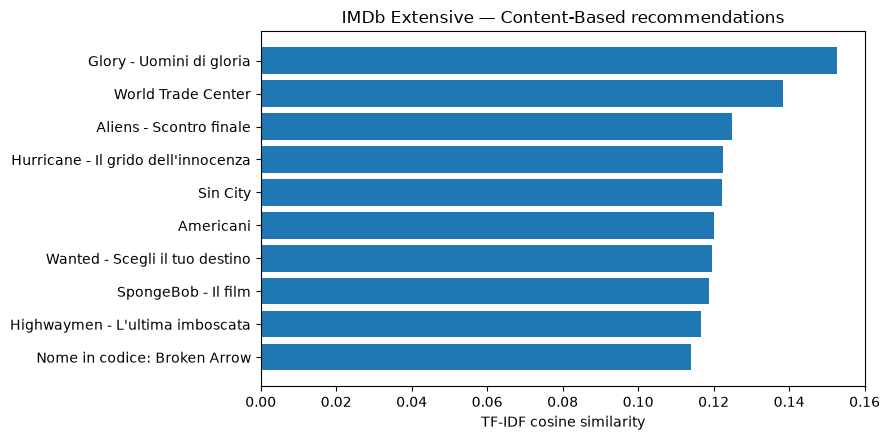

In [5]:
imdb_text=(imdb_movies.genre.str.replace(',',' ',regex=False)+' '+
           imdb_movies.director.str.replace(',',' ',regex=False)+' '+
           imdb_movies.actors.str.replace(',',' ',regex=False)+' '+imdb_movies.description)
imdb_vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=6000)
imdb_features=imdb_vectorizer.fit_transform(imdb_text)
imdb_title=str(imdb_movies.iloc[0].title)
imdb_content=recommend_by_content(imdb_movies,imdb_features,imdb_title,k=10)
print('Selected IMDb title:',imdb_title)
display(imdb_content.round(4))
assert len(imdb_content)==10
fig,ax=plt.subplots(figsize=(9,4.5));table=imdb_content.iloc[::-1]
ax.barh(table.title.str.slice(0,38),table.cosine_similarity)
ax.set(title='IMDb Extensive — Content-Based recommendations',xlabel='TF-IDF cosine similarity')
fig.tight_layout();plt.show()

### B3. Task 2 — Collaborative approximation using IMDb rating cohorts

The 6×N matrix represents **group-average ratings** (1–10), withholding cells with fewer than 30 votes in a group. Pearson correlation between group rows is computed only where there are at least 15 co-rated titles. The model uses positive similarities to estimate missing group means.

**Evaluation:** hold out about 15% of valid group-average cells while leaving enough data in each group and movie. Fit similarities using *training cells only* and compare predictions with withheld observations. Also compare against a simple **training cohort mean** baseline. This is **not** a user-level recommender.

IMDb matrix dimensions (groups × movies): (6, 3000)


,Women 18–29,Women 30–44,Women 45+,Men 18–29,Men 30–44,Men 45+
Women 18–29,1.000,0.978,0.915,0.940,0.923,0.894
Women 30–44,0.978,1.000,0.952,0.937,0.948,0.936
Women 45+,0.915,0.952,1.000,0.870,0.893,0.950
Men 18–29,0.940,0.937,0.870,1.000,0.984,0.935
Men 30–44,0.923,0.948,0.893,0.984,1.000,0.964
Men 45+,0.894,0.936,0.950,0.935,0.964,1.000


,Value
Held-out group means,2700.000000
MAE,0.183546
RMSE,0.247744
Training-group-mean baseline MAE,0.704668


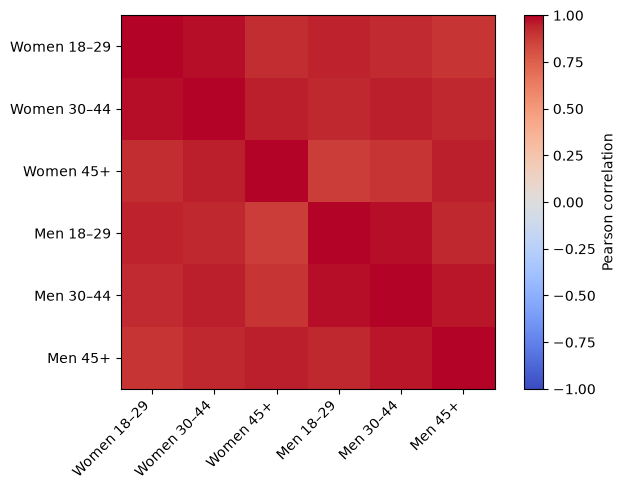

In [6]:
def make_cohort_matrix(frame,min_votes=30):
    rows=[]
    for mean_col,votes_col in COHORTS.values():
        mean=pd.to_numeric(frame[mean_col],errors='coerce')
        nvotes=pd.to_numeric(frame[votes_col],errors='coerce').fillna(0)
        rows.append(mean.where(mean.between(1,10)&nvotes.ge(min_votes)).to_numpy(float))
    return pd.DataFrame(rows,index=list(COHORTS),columns=frame.imdb_title_id.tolist())

def group_similarity(groups,min_overlap=15):
    x=groups.to_numpy(float);n=x.shape[0];sim=np.eye(n)
    for i in range(n):
        for j in range(i+1,n):
            valid=np.isfinite(x[i])&np.isfinite(x[j])
            if valid.sum()>=min_overlap and np.std(x[i,valid])>1e-12 and np.std(x[j,valid])>1e-12:
                s=np.corrcoef(x[i,valid],x[j,valid])[0,1]
                sim[i,j]=sim[j,i]=float(np.clip(s,-1,1)) if np.isfinite(s) else 0.0
            else:sim[i,j]=sim[j,i]=0.0
    return pd.DataFrame(sim,index=groups.index,columns=groups.index)

def predict_group_average(groups,similarity,row,col):
    x=groups.to_numpy(float)
    group_av=np.nanmean(x,axis=1)
    global_mean=float(np.nanmean(x))
    base=float(group_av[row]) if np.isfinite(group_av[row]) else global_mean
    w=similarity.iloc[row].to_numpy(float).copy();w[row]=0
    good=(w>0)&np.isfinite(x[:,col])&np.isfinite(group_av)
    if not good.any():return float(np.clip(base,1,10))
    result=base+np.dot(w[good],x[good,col]-group_av[good])/w[good].sum()
    return float(np.clip(result,1,10))

def evaluate_groups(groups,seed=42,fraction=0.15):
    x=groups.to_numpy(float)
    pairs=np.argwhere(np.isfinite(x))
    if len(pairs)<60:raise ValueError('Need at least 60 observed demographic averages for validation')
    rng=np.random.default_rng(seed);rng.shuffle(pairs)
    train=groups.copy()
    withheld=[];max_holdout=max(1,round(len(pairs)*fraction))
    for row,col in pairs:
        if len(withheld)>=max_holdout:break
        if train.iloc[row].notna().sum()<=15 or train.iloc[:,col].notna().sum()<=2:continue
        withheld.append((int(row),int(col),float(groups.iloc[row,col])))
        train.iloc[row,col]=np.nan
    if not withheld:raise ValueError('Unable to select any evaluable holdout')
    sims=group_similarity(train)
    y_true=np.array([value for _,_,value in withheld])
    y_pred=np.array([predict_group_average(train,sims,row,col) for row,col,_ in withheld])
    group_means=np.nanmean(train.to_numpy(float),axis=1)
    baseline=np.array([group_means[row] for row,_,_ in withheld])
    diff=y_pred-y_true
    return {'Held-out group means':len(y_true),'MAE':float(np.mean(abs(diff))),
            'RMSE':float(np.sqrt(np.mean(diff**2))),
            'Training-group-mean baseline MAE':float(np.mean(abs(baseline-y_true)))},train

imdb_groups=make_cohort_matrix(imdb_movies)
imdb_sim=group_similarity(imdb_groups)
print('IMDb matrix dimensions (groups × movies):',imdb_groups.shape)
display(imdb_sim.round(3))
imdb_scores,imdb_train_groups=evaluate_groups(imdb_groups)
display(pd.DataFrame([imdb_scores]).T.rename(columns={0:'Value'}))
assert np.isfinite(imdb_scores['MAE'])
fig,ax=plt.subplots(figsize=(7,5))
heat=ax.imshow(imdb_sim.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),imdb_sim.columns,rotation=45,ha='right')
ax.set_yticks(range(6),imdb_sim.index)
fig.colorbar(heat,ax=ax,label='Pearson correlation');fig.tight_layout();plt.show()

In [7]:
# Example estimates for a named cohort. If no cells are missing, demonstrate estimates for sufficiently observed movies.
chosen_group='Women 18–29'; row=list(imdb_groups.index).index(chosen_group)
available=np.flatnonzero(imdb_groups.iloc[row].isna().to_numpy() & (imdb_groups.notna().sum(axis=0).to_numpy()>=2))
reason='Missing group-average estimates'
if not len(available):
    available=np.flatnonzero(imdb_groups.notna().sum(axis=0).to_numpy()>=3)
    reason='Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)'
if not len(available):raise ValueError('Not enough IMDb group-mean observations for ranking')
est=np.array([predict_group_average(imdb_groups,imdb_sim,row,int(j)) for j in available])
order=np.argsort(-est)[:10]
keys=imdb_groups.columns[available[order]]
imdb_group_top=imdb_movies.set_index('imdb_title_id').loc[keys,['title','genre','avg_vote']].copy()
imdb_group_top['estimated_group_average']=est[order]
print('IMDb group:',chosen_group,'|',reason)
display(imdb_group_top.reset_index())

IMDb group: Women 18–29 | Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)


,imdb_title_id,title,genre,avg_vote,estimated_group_average
0,tt0111161,Le ali della libertà,Drama,9.3,9.369949
1,tt0068646,Il padrino,"Crime, Drama",9.2,9.247216
2,tt0071562,Il padrino - Parte II,"Crime, Drama",9.0,9.047216
3,tt0108052,Schindler's List,"Biography, Drama, History",8.9,9.030874
4,tt0050083,La parola ai giurati,"Crime, Drama",8.9,8.990699
5,tt0167260,Il Signore degli Anelli - Il ritorno del re,"Action, Adventure, Drama",8.9,8.971838
6,tt0120737,Il Signore degli Anelli - La compagnia dell'An...,"Action, Adventure, Drama",8.8,8.930058
7,tt0468569,Il cavaliere oscuro,"Action, Crime, Drama",9.0,8.873832
8,tt0110912,Pulp Fiction,"Crime, Drama",8.9,8.867750
9,tt0109830,Forrest Gump,"Drama, Romance",8.8,8.831569


## Part II — My optional MovieLens/TMDB classroom extension

I use authentic embedded snapshots of the public MovieLens/TMDB dataset; my original classroom source is separate. I can also retrieve `movies_metadata.csv`, `links_small.csv` and `ratings_small.csv` from [Rounak Banik's public Kaggle collection](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset). I use the public dataset as **independent source material** and do not assert that it is byte-for-byte the same as the teacher ZIP.

I deliberately **do not download the very large `ratings.csv`** by default: the model trains on the complete 100,004-rating `ratings_small.csv` when available. If I have the original teacher ZIP or `ratings.csv` locally, I additionally inspect its first 20,000 rows. If the optional MovieLens sources are unreachable, I clearly label the classroom extension as unavailable and keep the two IMDb assignment tasks executable.


In [8]:
CLASSROOM_FILES=('movies_metadata.csv','links_small.csv','ratings_small.csv')
class_zip=find_file('Assignment 8-machinelearning.zip')
CLASSROOM_SOURCE='Instructor-supplied ZIP' if class_zip else 'public Kaggle collection / documented mirror'
CLASSROOM_READY=True
CLASSROOM_PROBLEMS=[]

# Load only the files required by my two classroom models.
def read_classroom(filename, nrows=None, optional=False):
    if class_zip is not None:
        try:
            with ZipFile(class_zip) as archive:
                matches=[name for name in archive.namelist()
                    if Path(name).name==filename and '__MACOSX' not in name]
                if len(matches)==1:
                    with archive.open(matches[0]) as stream:
                        return pd.read_csv(stream,low_memory=False,nrows=nrows)
        except Exception as exc:
            CLASSROOM_PROBLEMS.append('Class ZIP '+filename+': '+str(exc)[:180])
    # Existing extracted CSV, attached Kaggle CSV, or automatic public Kaggle download.
    if filename!='ratings.csv':
        url='https://raw.githubusercontent.com/nmsohn/kaggle-movie/master/'+filename
        path=acquire(filename,CLASSROOM_KAGGLE,mirror_url=url,optional=True)
    else:
        path=find_file(filename)  # Intentionally no huge automatic download.
    if path is None:
        if not optional:CLASSROOM_PROBLEMS.append('Missing authentic classroom CSV: '+filename)
        return None
    return pd.read_csv(path,low_memory=False,nrows=nrows)

ml_metadata=read_classroom('movies_metadata.csv')
ml_links=read_classroom('links_small.csv')
ml_ratings=read_classroom('ratings_small.csv')
CLASSROOM_READY=all(v is not None for v in (ml_metadata,ml_links,ml_ratings))
ml_large_sample=read_classroom('ratings.csv',nrows=20000,optional=True)
if CLASSROOM_READY:
    assert {'id','title','overview'}.issubset(ml_metadata.columns)
    assert {'movieId','tmdbId'}.issubset(ml_links.columns)
    assert {'userId','movieId','rating'}.issubset(ml_ratings.columns)
    assert ml_ratings['rating'].between(0.5,5).all()
    ml_summary=pd.DataFrame([
      ('movies_metadata.csv',len(ml_metadata),'full public/classroom file'),
      ('links_small.csv',len(ml_links),'full public/classroom file'),
      ('ratings_small.csv',len(ml_ratings),'full public/classroom file'),
      ('ratings.csv',len(ml_large_sample) if ml_large_sample is not None else 0,
         'only first 20,000 rows if locally available; otherwise NOT DOWNLOADED')
     ],columns=['Classroom file','Rows read','Coverage'])
    print('Classroom data origin:',CLASSROOM_SOURCE)
    display(ml_summary)
else:
    print('OPTIONAL CLASSROOM EXTENSION SKIPPED: no authentic MovieLens dataset was available.')
    print('The two IMDb Extensive assignment tasks above completed independently.')
    for reason in CLASSROOM_PROBLEMS: print(' -',reason)
    print('I can rerun this section later after attaching the original ZIP from my instructor.')


Using supplied file: movies_metadata.csv
Using supplied file: links_small.csv
Using supplied file: ratings_small.csv
Classroom data origin: public Kaggle collection / documented mirror


,Classroom file,Rows read,Coverage
0,movies_metadata.csv,9099,full public/classroom file
1,links_small.csv,9125,full public/classroom file
2,ratings_small.csv,100004,full public/classroom file
3,ratings.csv,0,"only first 20,000 rows if locally available; o..."


### A2. Content-Based Filtering (classroom example)

The instructor's example uses a movie overview (and where available, its tagline). We keep that idea and use `links_small.csv` to select the MovieLens/TMDB classroom subset. **TF-IDF** makes the text numeric; **cosine similarity** measures similarity between the chosen title and candidate films. We calculate similarities **on demand**, not a large dense all-to-all matrix.

In [9]:
if CLASSROOM_READY:
    ml_metadata = ml_metadata.copy()
    ml_metadata['tmdb_numeric'] = pd.to_numeric(ml_metadata['id'], errors='coerce')
    ml_links = ml_links.copy()
    ml_links['tmdb_numeric'] = pd.to_numeric(ml_links['tmdbId'], errors='coerce')
    subset_ids = set(ml_links['tmdb_numeric'].dropna().astype('int64').tolist())
    ml_small = ml_metadata.loc[ml_metadata['tmdb_numeric'].isin(subset_ids)].copy()
    ml_small = ml_small.dropna(subset=['title']).drop_duplicates('tmdb_numeric').reset_index(drop=True)
    ml_small['overview'] = ml_small['overview'].fillna('').astype(str)
    ml_small['tagline'] = ml_small.get('tagline',pd.Series('',index=ml_small.index)).fillna('').astype(str)
    ml_small['description'] = (ml_small['overview']+' '+ml_small['tagline']).str.strip()
    ml_small = ml_small.loc[ml_small['description'].str.len()>10].reset_index(drop=True)
    assert len(ml_small) >= 5, 'Not enough classroom movies with useful descriptions'
    ml_tfidf = TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=6500)
    ml_X = ml_tfidf.fit_transform(ml_small['description'])

    ml_title = 'The Dark Knight' if ml_small['title'].eq('The Dark Knight').any() else str(ml_small.iloc[0]['title'])
    ml_content = recommend_by_content(ml_small,ml_X,ml_title,k=10)
    print('Classroom selected movie:',ml_title,'| searchable movies:',len(ml_small))
    display(ml_content.round(4))
    assert len(ml_content) == 10
else:
    print("Skipped optional MovieLens experiment: authentic classroom data unavailable.")


Classroom selected movie: The Dark Knight | searchable movies: 9069


,title,cosine_similarity
0,The Dark Knight Rises,0.3136
1,Batman Returns,0.2764
2,Batman Forever,0.2601
3,"Batman: The Dark Knight Returns, Part 2",0.2524
4,Batman: Under the Red Hood,0.2450
5,Batman: Mask of the Phantasm,0.2170
6,Batman: Year One,0.2105
7,"Batman: The Dark Knight Returns, Part 1",0.2041
8,JFK,0.1852
9,Batman Begins,0.1775


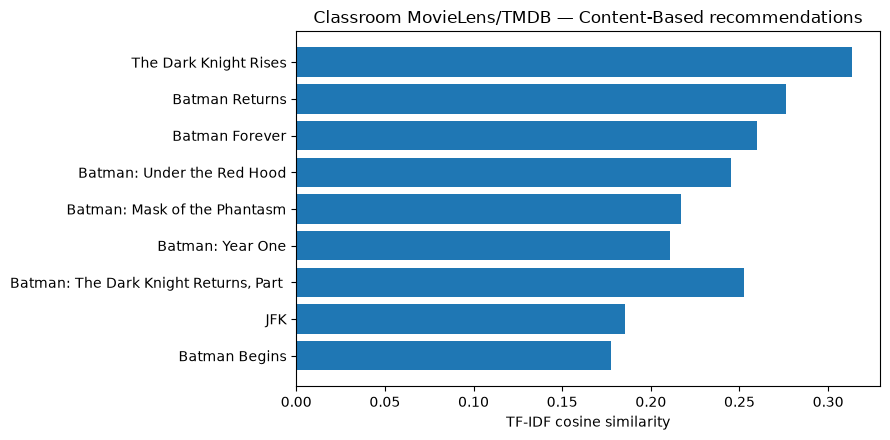

In [10]:
if CLASSROOM_READY:
    fig,ax=plt.subplots(figsize=(9,4.5))
    chart=ml_content.iloc[::-1]
    ax.barh(chart['title'].str.slice(0,38),chart['cosine_similarity'])
    ax.set(xlabel='TF-IDF cosine similarity',title='Classroom MovieLens/TMDB — Content-Based recommendations')
    fig.tight_layout();plt.show()
else:
    print("Skipped optional MovieLens experiment: authentic classroom data unavailable.")


### A3. Collaborative Filtering (user-based, MovieLens)

`ratings_small.csv` stores **individual** ratings. We split events 80/20 (`random_state=42`), calculate **user-user** similarities from **training data only**, and predict held-out ratings with up to 25 positively similar neighbors. This is neighborhood-based collaborative filtering, **not Surprise SVD/matrix factorization**. The course notebook also illustrates Surprise/SVD; here we use a compatible installation-free technique for a reliable and explainable single-notebook submission.

In [11]:
if CLASSROOM_READY:
    ml_events = ml_ratings[['userId','movieId','rating']].dropna().copy()
    ml_events = ml_events.groupby(['userId','movieId'],as_index=False)['rating'].mean()
    ml_train,ml_test = train_test_split(ml_events,test_size=0.20,random_state=42)
    ml_users = np.sort(ml_train.userId.unique()); ml_items = np.sort(ml_train.movieId.unique())
    ml_uid={u:i for i,u in enumerate(ml_users)}; ml_mid={m:i for i,m in enumerate(ml_items)}
    ml_rr=ml_train.userId.map(ml_uid).to_numpy(); ml_cc=ml_train.movieId.map(ml_mid).to_numpy()
    ml_vv=ml_train.rating.to_numpy(dtype=float)
    ml_user_av=ml_train.groupby('userId').rating.mean();ml_global=float(ml_train.rating.mean())
    ml_means = np.array([ml_user_av.get(u,ml_global) for u in ml_users])
    ml_mat=csr_matrix((ml_vv,(ml_rr,ml_cc)),shape=(len(ml_users),len(ml_items)))
    ml_centered=csr_matrix((ml_vv-ml_means[ml_rr],(ml_rr,ml_cc)),shape=ml_mat.shape)
    ml_sim=cosine_similarity(ml_centered);np.fill_diagonal(ml_sim,0)
    ml_columns=ml_mat.tocsc()

    def predict_rating(user,movie):
        if user not in ml_uid: return ml_global
        row=ml_uid[user]
        if movie not in ml_mid: return float(np.clip(ml_means[row],0.5,5))
        col=ml_mid[movie]
        ratings_col=ml_columns.getcol(col)
        neighbors=ratings_col.indices
        ratings_values=ratings_col.data
        pos=ml_sim[row,neighbors] > 0
        neighbors=neighbors[pos];ratings_values=ratings_values[pos]
        if not len(neighbors):return float(np.clip(ml_means[row],0.5,5))
        top=np.argsort(-ml_sim[row,neighbors])[:25]
        neighbors=neighbors[top];ratings_values=ratings_values[top]
        w=ml_sim[row,neighbors]
        est=ml_means[row]+np.dot(w,ratings_values-ml_means[neighbors])/w.sum()
        return float(np.clip(est,0.5,5))

    # Only evaluate ratings with known training users and items. Report coverage.
    ml_eval=ml_test.loc[ml_test.userId.isin(ml_uid)&ml_test.movieId.isin(ml_mid)].copy()
    assert not ml_eval.empty
    ml_predictions = np.array([predict_rating(u,m) for u,m in ml_eval[['userId','movieId']].itertuples(index=False,name=None)])
    ml_truth=ml_eval.rating.to_numpy(float)
    ml_errors=ml_predictions-ml_truth
    ml_mae=float(np.mean(np.abs(ml_errors)))
    ml_rmse=float(np.sqrt(np.mean(ml_errors**2)))
    # Baseline is the user average from training data only; same evaluation rows.
    ml_baseline=np.array([ml_means[ml_uid[u]] for u in ml_eval.userId])
    ml_baseline_mae=float(np.mean(np.abs(ml_baseline-ml_truth)))
    ml_metrics=pd.DataFrame([('Train ratings',len(ml_train)),('Held-out test ratings',len(ml_test)),
     ('Evaluable test ratings',len(ml_eval)),('Coverage',len(ml_eval)/len(ml_test)),
     ('User-based MAE',ml_mae),('User-based RMSE',ml_rmse),('User-mean baseline MAE',ml_baseline_mae)],columns=['Metric','Value'])
    display(ml_metrics)
    assert np.isfinite(ml_mae) and np.isfinite(ml_rmse)
else:
    print("Skipped optional MovieLens experiment: authentic classroom data unavailable.")


,Metric,Value
0,Train ratings,80003.000000
1,Held-out test ratings,20001.000000
2,Evaluable test ratings,19259.000000
3,Coverage,0.962902
4,User-based MAE,0.685100
5,User-based RMSE,0.900277
6,User-mean baseline MAE,0.747267


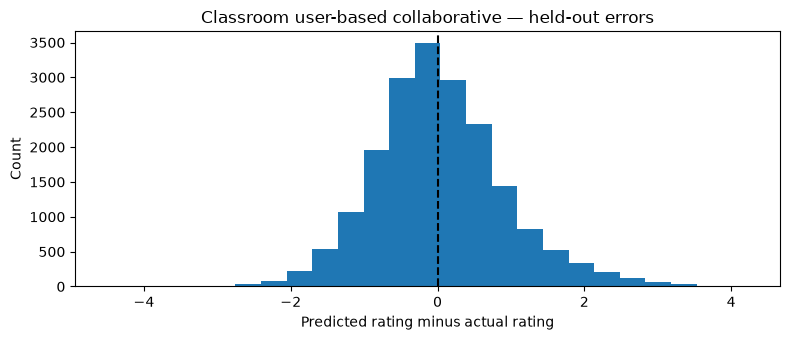

In [12]:
if CLASSROOM_READY:
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.hist(ml_errors,bins=25)
    ax.axvline(0,linestyle='--',color='black')
    ax.set(xlabel='Predicted rating minus actual rating',ylabel='Count',title='Classroom user-based collaborative — held-out errors')
    fig.tight_layout();plt.show()
else:
    print("Skipped optional MovieLens experiment: authentic classroom data unavailable.")


## Part C — My results and interpretation

I report IMDb cohort-average errors (1–10) separately from MovieLens individual-rating errors (0.5–5). Their numerical MAE/RMSE values are **not directly comparable** because they estimate different targets on different scales.

If I can download the optional classroom files, I show them next to IMDb with source attribution. If not, I submit the **two completed IMDb tasks** without pretending MovieLens results exist. The interactive website always uses fictional teaching records and is not evidence of real predictions.


In [13]:
results=[
 {'Source':'IMDb Extensive — assignment','Approach':'Content-Based',
  'Output':f'{len(imdb_content)} related titles','Metric':'TF-IDF cosine similarity'},
 {'Source':'IMDb Extensive — assignment','Approach':'Cohort-average Collaborative',
  'Output':f'{imdb_scores["Held-out group means"]} held-out cohort means',
  'Metric':f'MAE {imdb_scores["MAE"]:.4f}; RMSE {imdb_scores["RMSE"]:.4f}; baseline MAE {imdb_scores["Training-group-mean baseline MAE"]:.4f}'}]
if CLASSROOM_READY:
    results.extend([
      {'Source':'MovieLens/TMDB — classroom extension','Approach':'Content-Based',
       'Output':f'{len(ml_content)} related titles','Metric':'TF-IDF cosine similarity'},
      {'Source':'MovieLens/TMDB — classroom extension','Approach':'Individual-rating Collaborative',
       'Output':f'{len(ml_eval)} held-out individual ratings',
       'Metric':f'MAE {ml_mae:.4f}; RMSE {ml_rmse:.4f}; baseline MAE {ml_baseline_mae:.4f}'}])
else:
    print('Classroom extension was not executed; no MovieLens metrics are represented here.')
final_comparison=pd.DataFrame(results)
display(final_comparison)
print('PASS — My two IMDb assignment methods completed with source data.')
if CLASSROOM_READY: print('PASS — My independent MovieLens/TMDB classroom extension completed.')


,Source,Approach,Output,Metric
0,IMDb Extensive — assignment,Content-Based,10 related titles,TF-IDF cosine similarity
1,IMDb Extensive — assignment,Cohort-average Collaborative,2700 held-out cohort means,MAE 0.1835; RMSE 0.2477; baseline MAE 0.7047
2,MovieLens/TMDB — classroom extension,Content-Based,10 related titles,TF-IDF cosine similarity
3,MovieLens/TMDB — classroom extension,Individual-rating Collaborative,19259 held-out individual ratings,MAE 0.6851; RMSE 0.9003; baseline MAE 0.7473


PASS — My two IMDb assignment methods completed with source data.
PASS — My independent MovieLens/TMDB classroom extension completed.


## My conclusions and academic integrity

I completed the two assignment methods on IMDb Extensive. My Content-Based model compares what a movie is about, while the rating-pattern model estimates **demographic cohort means**, not individual preferences. I never call the latter a user-level Surprise/SVD recommender.

If public access to MovieLens or my original classroom ZIP is available, I also complete my **separately labeled classroom extension**, where user–movie ratings make it possible to evaluate individual-rating predictions. I explicitly document which version of MovieLens was used, including whether it came from the teacher ZIP or a publicly available Kaggle/mirror dataset.

My evaluation with held-out observations and separate baselines measures **different outcomes** across IMDb and MovieLens; I do not compare MAE/RMSE across their different scales as though they were interchangeable.

**How I reproduce my work:** I open my single notebook, run all cells, verify real-source provenance and results, save the notebook **with outputs**, and submit that executed file. I do not present synthetic tests, fictional website scores or historical notebook results as a fresh evaluation.

**References:** Beth Muturi, CAI2100C *Machine Learning Foundations*, Assignment 8; [IMDb Extensive, Stefano Leone](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset); [The Movies Dataset, Rounak Banik](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset); [official Kagglehub documentation](https://github.com/Kaggle/kagglehub); [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
